# LFM3をGoogle Colab T4で試す

[Google Colabで開く](https://colab.research.google.com/github/Sunwood-ai-labs/lfm3-colab-lab/blob/main/notebooks/LFM3_Colab_T4.ipynb)

## まずは3つ

1. Colabのランタイムの種類をGPU（T4）にします。
2. ランタイムから「すべてのセルを実行」を選びます。
3. 各モデルの節で、回答と計測値を確認します。

**初回の目安** 重みのダウンロードを含めて10〜30分ほどです。これは推定値で、Colabの起動待ちや通信状況で前後します。前回の測定にはダウンロードとモデルの読み込みを含みません。ノートブックはT4以外へ切り替えず、CPUでも続行しません。

**結果の日付** 下の参考値は2026-10-28に記録したT4・FP16の実行結果です。今回の実行結果は各モデルの節に別途表示します。

## 参考値：2026-10-28のT4実行

6モデルすべてが読み込みと推論まで進みました。これは固定した代表ケースの結果で、回答の誤りも含みます。今回の実行の結果ではありません。

- **LFM3-1.7B** はテキストの言い換えと計算ツールを試します。言い換えの中央値は0.57秒。言い換えと加算ツールは6/6ケース通過しました。最大VRAM（allocated / reserved）: 3.24 / 3.26 GiB
- **LFM3-VL-2B** は画像と動画を扱います。画像ツールと動画の色変化の9/9ケースが通過しました。3秒動画への回答は1.23秒。最大VRAM（allocated / reserved）: 3.88 / 3.96 GiB
- **LFM3-Audio-2B** は音声認識・生成・翻訳・説明・対話を試します。英語の音声対話とツールは各3/3回、日本語は各0/3回でした。最大VRAM（allocated / reserved）: 3.86 / 3.90 GiB
- **LFM3-Omni-2B** は画像・音声・動画を組み合わせます。9ケース中3ケースが通過しました。赤い四角への質問は3/3回正答し、青い四角への質問は3回とも無回答でした。最大VRAM（allocated / reserved）: 4.68 / 4.80 GiB
- **d1-2B** は決まった形式で分類や抽出を行います。2つのタスク群が通過しました。分類・抽出と、画像の位置・個数を確認した結果です。最大VRAM（allocated / reserved）: 3.71 / 5.15 GiB
- **d1-Omni-2B** は構造化判断に音声を加えます。4つのタスク群のうち3つが通過しました。画像と音声に青の7を尋ねたケースでは3と回答しました。最大VRAM（allocated / reserved）: 4.19 / 5.57 GiB

**数値の見方** VRAMはPyTorchの最大allocated / reservedです。GPU全体の使用量ではありません。速度は推論区間の時間で、モデルのダウンロードと読み込みは含みません。ウォームアップや前処理の扱いはモデルごとに異なります。入力とタスクも異なるため、速度を単純に順位づけできません。音声の波形が生成されたことも、回答の意味が正しいことを示しません。

## T4と実行回数を確認する

このノートブックはTesla T4だけで実行します。GPUを割り当てられなかった場合や、別のGPUが選ばれた場合は最初のセルで停止します。

最初は各モデルの固定ケースを1回ずつ試します。繰り返して速度を比べたい場合は、次のセルのREPEATSを3に変えてください。1回だけの計測値は変動するため、性能の順位付けには使わないでください。

In [ ]:
import torch

REPEATS = 1

if not torch.cuda.is_available():
    raise RuntimeError("ランタイムの種類をGPU（T4）に変更してから再実行してください。")

GPU_NAME = torch.cuda.get_device_name(0)
if "T4" not in GPU_NAME:
    raise RuntimeError(f"このノートブックはT4専用です。現在のGPU: {GPU_NAME}")

print(f"GPU: {GPU_NAME} / CUDA: {torch.version.cuda} / repeats: {REPEATS}")

GPU: Tesla T4 / CUDA: 13.0 / repeats: 1


## 公開コードを固定して取得する

ノートブック内にはモデル実装を埋め込まず、公開リポジトリの40桁コミットだけを取得します。GitHubへのログイン情報や個人用のパスは使いません。

取得先は [https://github.com/Sunwood-ai-labs/lfm3-colab-lab](https://github.com/Sunwood-ai-labs/lfm3-colab-lab) です。

In [ ]:
import re
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/Sunwood-ai-labs/lfm3-colab-lab.git"
CODE_REF = "1fda1d099245243e9af2ab235f34280a7230779e"
REPO_ROOT = Path("/content/lfm3-colab-lab")

if not re.fullmatch(r"[0-9a-f]{40}", CODE_REF):
    raise ValueError("CODE_REFに公開済みの40桁コミットSHAを設定してください。")

if REPO_ROOT.exists() and not (REPO_ROOT / ".git").exists():
    raise RuntimeError(f"既存の保存先がGitリポジトリではありません: {REPO_ROOT}")
if not REPO_ROOT.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_ROOT)], check=True)
remote = subprocess.check_output(
    ["git", "-C", str(REPO_ROOT), "remote", "get-url", "origin"], text=True
).strip()
if remote.removesuffix(".git").lower() != REPO_URL.removesuffix(".git").lower():
    raise RuntimeError(f"保存先のoriginが想定と異なります: {remote}")

def run_git(args):
    subprocess.run(["git", "-C", str(REPO_ROOT), *args], check=True)

run_git(["fetch", "--depth", "1", "origin", CODE_REF])
run_git(["checkout", "--detach", CODE_REF])
resolved = subprocess.check_output(["git", "-C", str(REPO_ROOT), "rev-parse", "HEAD"], text=True).strip().lower()
if resolved != CODE_REF:
    raise RuntimeError(f"取得したコミットが一致しません: {resolved}")
print(f"コードのコミット: {resolved}")

コードのコミット: 1fda1d099245243e9af2ab235f34280a7230779e


## 依存パッケージを入れる

最初のセルはdry-runでTorchとCUDA関連の変更計画を調べます。変更を検出した場合は処理を止めます。確認が通ったら次のセルを実行してください。requirements-colab.txtと実験パッケージを入れますが、Torchの依存関係は追加しません。

In [ ]:
import importlib.metadata as metadata
import json
import subprocess
import sys

def runtime_snapshot():
    installed = {re.sub(r"[-_.]+", "-", dist.metadata.get("Name", "")).lower(): dist.version for dist in metadata.distributions()}
    protected = {name: ver for name, ver in installed.items() if name in {"torch", "torchvision", "torchaudio", "triton"} or name.startswith(("nvidia-", "cuda-"))}
    return (installed.get("torch"), torch.version.cuda, protected)

def pip_step(args):
    done = subprocess.run(args, capture_output=True, text=True)
    if done.returncode:
        raise RuntimeError((done.stderr or done.stdout)[-2500:])

before = runtime_snapshot()
requirement = REPO_ROOT / "requirements-colab.txt"
if not requirement.is_file():
    raise FileNotFoundError(f"requirements-colab.txtがありません: {requirement}")
plan_file = "/tmp/lfm3-pip-plan.json"
pip_step([
    sys.executable, "-m", "pip", "install", "--dry-run",
    "--report", str(plan_file), "--requirement", str(requirement)
])
with open(plan_file, encoding="utf-8") as report:
    planned = {re.sub(r"[-_.]+", "-", item["metadata"]["name"]).lower() for item in json.load(report).get("install", [])}
blocked = sorted(name for name in planned if name in {"torch", "torchvision", "torchaudio", "triton"} or name.startswith(("nvidia-", "cuda-")))
if blocked:
    raise RuntimeError(f"Torch/CUDA関連を変更する計画のため中止しました: {blocked}")
print(f"Torch {before[0]} / CUDA {before[1]}の変更計画はありません。")

Torch 2.11.0+cu130 / CUDA 13.0の変更計画はありません。


In [ ]:
pip_step([sys.executable, "-m", "pip", "install", "--requirement", str(requirement)])
pip_step([sys.executable, "-m", "pip", "install", "--no-deps", "-e", str(REPO_ROOT)])
if runtime_snapshot() != before:
    raise RuntimeError("TorchまたはCUDA関連のバージョンが変わりました。ランタイムを再起動してください。")
import importlib
sys.path.insert(0, str(REPO_ROOT / "src"))
for name in list(sys.modules):
    if name == "lfm3_lab" or name.startswith("lfm3_lab."):
        del sys.modules[name]
importlib.invalidate_caches()
print(f"依存関係を設定しました。Torch {before[0]} / CUDA {before[1]} は維持されています。")

依存関係を設定しました。Torch 2.11.0+cu130 / CUDA 13.0 は維持されています。


## 固定入力を用意して確認する

prepareはこのノートブックで使うサンプル入力を準備します。次のセルで画像と音声・動画の入力一覧を確認してから、モデルを実行します。

In [ ]:
from lfm3_lab import Lab

lab = Lab(output_dir="/content/lfm3-results")
prepared = lab.prepare()

固定入力の準備を開始しました。実行ログを保存しています。


入力,SHA-256先頭12桁,バイト
manifest.json,7ac0f77393e1,2399
scene.png,7a287aa6fba8,4503
scene_video.mp4,b23782fe625d,4170
sequence_video.mp4,d41ed0807878,2746
speech_reference.json,69e3b7c968ed,996
speech_reference.wav,00b5efdbd751,222764
tone.wav,30044108d3c1,64044
voice_english_reference.wav,204d2beb6f73,180524
voice_math_question.wav,dbb0f57b3e07,176684
voice_math_question_en.wav,322ef7e987e1,99884


**画像** `scene.png`

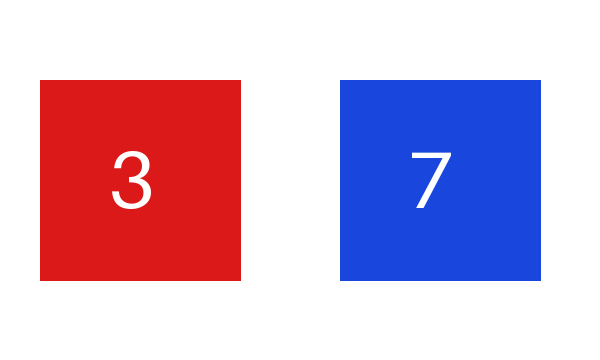

**音声** `speech_reference.wav`

公開参照音声を再生しています。ASRや音声理解の採点結果は実験表に示します。

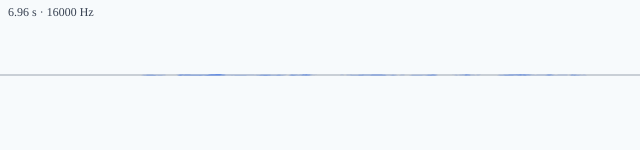

**動画** `sequence_video.mp4`

In [ ]:
inputs = lab.show_inputs()

### Text: 文章とツール呼び出し

日本語の言い換えと、実際に加算ツールを呼ぶケースを試します。前回は言い換えが中央値0.57秒で、言い換えと加算ツールの計6ケースが通過しました。

この節の出力には今回の実行結果が表示されます。以前の代表値とは分けて確認してください。

テキスト（LFM3-1.7B）を開始しました。実行ログを保存しています。


**画像** `scene.png`

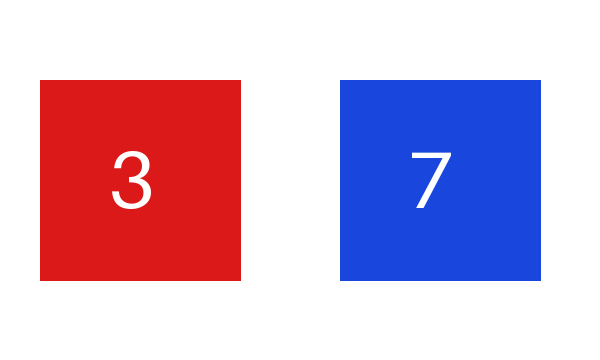

task_id,stage,標本数,中央値,生成速度,RTF,最大allocated,最大reserved
text_japanese_rephrase_no_think,answer,1,0.51 秒,27.40 token/秒,未計測,3.23 GiB,3.25 GiB
text_tool_add_numbers_no_think,final_response,1,0.58 秒,27.46 token/秒,未計測,3.24 GiB,3.25 GiB
text_tool_add_numbers_no_think,tool_call,1,0.90 秒,26.75 token/秒,未計測,3.24 GiB,3.25 GiB


In [ ]:
text_result = lab.run("text", repeats=REPEATS)
shown = lab.show(text_result)

### 画像と動画

画像を見た計算ツールの呼び出しと、動画の色の変化を試します。前回はこの2種類の9ケースが通過し、3秒の動画への回答は1.23秒でした。

この節の出力には今回の実行結果が表示されます。以前の代表値とは分けて確認してください。

In [ ]:
vision_result = lab.run("vision", repeats=REPEATS)
shown = lab.show(vision_result)

画像・動画（LFM3-VL-2B）を開始しました。実行ログを保存しています。


画像・動画（LFM3-VL-2B）を実行中です（経過時間：30秒）。


**動画** `sequence_video.mp4`

task_id,stage,標本数,中央値,生成速度,RTF,最大allocated,最大reserved
vision_image_addition_tool_no_think,final_response,1,0.22 秒,18.51 token/秒,未計測,3.68 GiB,3.96 GiB
vision_image_addition_tool_no_think,tool_call,1,0.97 秒,24.85 token/秒,未計測,3.68 GiB,3.96 GiB
vision_video_temporal_no_think,answer,1,1.14 秒,22.72 token/秒,未計測,3.88 GiB,3.96 GiB
vision_video_temporal_thinking,answer,1,10.45 秒,26.41 token/秒,未計測,3.88 GiB,3.96 GiB


### Audio: 音声を聞く・話す

文字起こし、音声生成、翻訳、音の説明、音声対話と音声からのツール呼び出しを試します。前回の英語音声対話と英語の音声ツールは各3/3回通過し、日本語の音声対話と音声ツールは各0/3回でした。6.96秒の日本語録音の文字起こしは0.69秒で、「群島」を「軍艦」と誤認しました。この1音声の文字誤り率は14.3%です。一般の日本語認識率を示す値ではありません。

この節の出力には今回の実行結果が表示されます。以前の代表値とは分けて確認してください。

音声（LFM3-Audio-2B）を開始しました。実行ログを保存しています。


音声（LFM3-Audio-2B）を実行中です（経過時間：30秒）。


音声（LFM3-Audio-2B）を実行中です（経過時間：1分）。


**音声** `tts-ja-blue-question-r1.wav`

TTS音声の波形とファイル形式を表示しています。発話内容は未採点です。

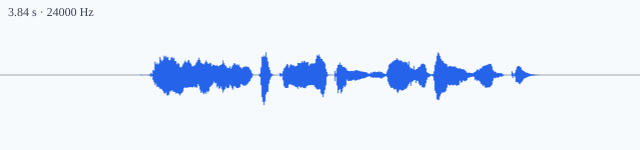

task_id,stage,標本数,中央値,生成速度,RTF,最大allocated,最大reserved
asr-en-synthetic-reference,asr,1,0.51 秒,未計測,未計測,3.85 GiB,3.89 GiB
asr-ja-human-reference,asr,1,2.05 秒,未計測,未計測,3.86 GiB,3.89 GiB
audio-understanding-tone,audio_understanding,1,1.32 秒,未計測,未計測,3.85 GiB,3.89 GiB
translation-ja-en-human-reference,translation,1,0.60 秒,未計測,未計測,3.86 GiB,3.89 GiB
tts-en-short-phrase,tts,1,3.52 秒,未計測,0.88,3.85 GiB,3.88 GiB
tts-fixture-voice_math_question,tts,1,3.19 秒,未計測,0.87,3.85 GiB,3.86 GiB
tts-fixture-voice_math_question_en,tts,1,1.84 秒,未計測,0.89,3.84 GiB,3.88 GiB
tts-fixture-voice_question_red,tts,1,5.48 秒,未計測,1.65,3.85 GiB,3.86 GiB
tts-fixture-voice_tool_request,tts,1,5.57 秒,未計測,0.85,3.85 GiB,3.88 GiB
tts-fixture-voice_tool_request_en,tts,1,3.39 秒,未計測,0.87,3.85 GiB,3.88 GiB


In [ ]:
# 音声出力が聞けても、回答内容が正しいとは限りません。
audio_result = lab.run("audio", repeats=REPEATS)
shown = lab.show(audio_result)

### Omni: 画像・音声・動画を組み合わせる

画像と音声、動画と音声を合わせた質問を試します。前回は9ケース中3ケースが通過しました。赤い四角への画像と音声の質問は3/3回正答し、青い四角への質問には3回とも答えませんでした。動画と音声の回答では、求めた数字を選べませんでした。

この節の出力には今回の実行結果が表示されます。以前の代表値とは分けて確認してください。

音声・動画（LFM3-Omni-2B）を開始しました。実行ログを保存しています。


音声・動画（LFM3-Omni-2B）を実行中です（経過時間：30秒）。


**画像** `scene.png`

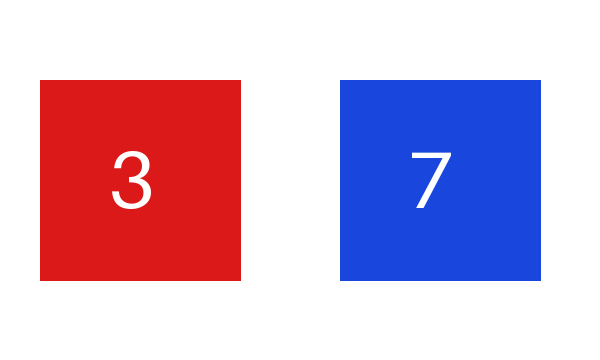

task_id,stage,標本数,中央値,生成速度,RTF,最大allocated,最大reserved
image-audio-blue-digit,image_audio,1,4.55 秒,未計測,未計測,4.29 GiB,4.34 GiB
image-audio-red-digit,image_audio,1,0.53 秒,未計測,未計測,4.29 GiB,4.34 GiB
video-audio-blue-digit,video_audio,1,0.99 秒,未計測,未計測,4.68 GiB,4.80 GiB


In [ ]:
omni_result = lab.run("omni", repeats=REPEATS)
shown = lab.show(omni_result)

### d1: 形式を決めて判断する

テキストの分類・項目抽出と、画像中の物体の位置や個数を決まった形式で返すケースを試します。前回は2つのタスク群が通過しました。テキスト判定は0.124秒、画像判定は0.173秒でした。請求書画像からの厳密なJSON抽出は0/10、テキストからのJSON抽出は15/15でした。

この節の出力には今回の実行結果が表示されます。以前の代表値とは分けて確認してください。

推論（d1-2B）を開始しました。実行ログを保存しています。


推論（d1-2B）を実行中です（経過時間：30秒）。


**画像** `scene.png`

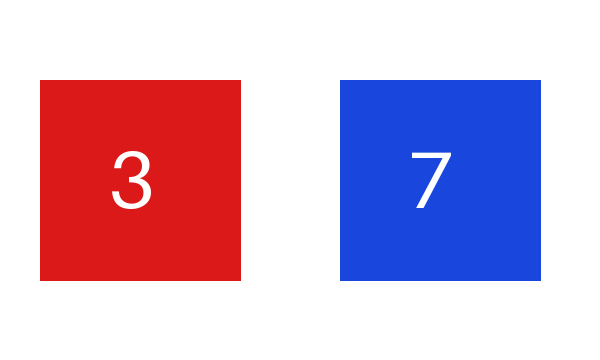

task_id,stage,標本数,中央値,生成速度,RTF,最大allocated,最大reserved
text_typed_decisions,system_one,1,0.12 秒,未計測,未計測,3.66 GiB,5.06 GiB
image_boxes_and_count,system_one,1,0.18 秒,未計測,未計測,3.71 GiB,5.15 GiB


In [ ]:
d1_result = lab.run("d1", repeats=REPEATS)
shown = lab.show(d1_result)

### d1-Omni: 音声も使う構造化判断

d1の形式化された判断に、音声分類や画像と音声を合わせた入力を加えます。前回は4つのタスク群のうち3つが通過しました。画像と音声に「青の7」を尋ねたケースでは「3」と回答しました。テキスト判定は0.122秒、画像判定は0.175秒、音声分類は0.077秒でした。

この節の出力には今回の実行結果が表示されます。以前の代表値とは分けて確認してください。

音声・推論（d1-Omni-2B）を開始しました。実行ログを保存しています。


音声・推論（d1-Omni-2B）を実行中です（経過時間：30秒）。


**音声** `voice_question.wav`

合成質問音声の波形と再生です。音声から答えを理解できたかは実験表で確認します。

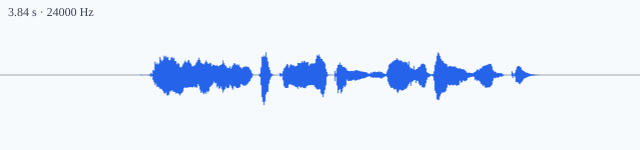

task_id,stage,標本数,中央値,生成速度,RTF,最大allocated,最大reserved
text_typed_decisions,system_one,1,0.12 秒,未計測,未計測,4.14 GiB,5.48 GiB
image_boxes_and_count,system_one,1,0.18 秒,未計測,未計測,4.19 GiB,5.57 GiB
public_audio_decisions,system_one,1,0.08 秒,未計測,未計測,4.08 GiB,5.57 GiB
spoken_question_with_image,system_one,1,0.15 秒,未計測,未計測,4.19 GiB,5.57 GiB


In [ ]:
# voice_question.wavはAudio suiteが用意します。この節だけを実行する場合は、先にAudio節を一度実行してください。
d1_omni_result = lab.run("d1_omni", repeats=REPEATS)
shown = lab.show(d1_omni_result)

## 入力を変えて文章の回答を試す

PROMPTの1行を書き換えて実行します。初期値も実際にモデルへ渡し、回答を表示します。自由入力には自動採点がありません。回答の内容は自分で確認してください。

run_textは直前のモデルをGPUから解放してからテキストモデルを読み込みます。

In [ ]:
PROMPT = "18 と 24 を足した答えを、一文で教えてください。"

answer = lab.run_text(PROMPT, repeats=1)
print(f"状態: {answer.status} / モデル: {answer.model_id}")
print(f"推論時間: {answer.elapsed_seconds:.2f} 秒")
print(f"入力: {answer.prompt}")
print(f"回答: {answer.answer}")

テキスト自由入力を開始しました。実行ログを保存しています。


状態: generated / モデル: LiquidAI/LFM3-1.7B
推論時間: 2.94 秒
入力: 18 と 24 を足した答えを、一文で教えてください。
回答: 18 と 24 を足すと、42 になります。一文で答えるなら「18 と 24 の和は 42 です。」となります。


## 結果を比べて保存する

各モデルの出力は秒単位の推論時間、GiB単位のallocated / reserved、ケースの回答と判定を表示します。測定条件と入力が異なるモデル間では、速度を順位として解釈しないでください。

次のセルを実行すると、summary・CSV・回答記録を含むZIPを作り、Colabからダウンロードします。音声の生成波形は、回答が正しいかの判定とは別に扱います。

In [ ]:
from google.colab import files

export_path = lab.export()
print(f"保存した結果: {export_path}")
download = files.download(str(export_path))

保存した結果: /content/lfm3-results/lfm3-results-export-20261028T140437259478Z-51299c0b.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>